In [ ]:
import numpy as np
import matplotlib.pyplot as plt

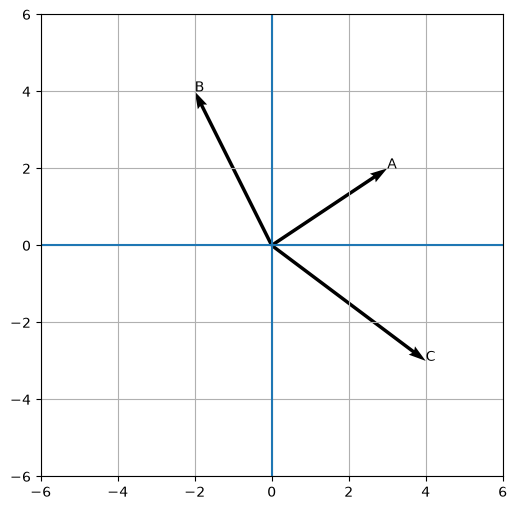

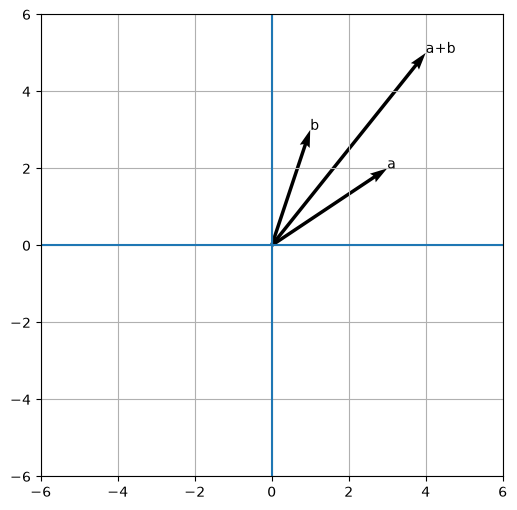

In [5]:
import numpy as np
import matplotlib.pyplot as plt


# Step 1: Define the drawing function
def draw_vectors(vectors, labels):

    fig, ax = plt.subplots(figsize=(6, 6))

    for v, label in zip(vectors, labels):

        ax.quiver(
            0, 0,
            v[0], v[1],
            angles='xy',
            scale_units='xy',
            scale=1
        )

        ax.text(v[0], v[1], label)

    ax.set_aspect('equal')
    ax.axhline(0)
    ax.axvline(0)
    ax.grid(True)

    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)

    plt.show()


# Step 2: Define vectors OUTSIDE the function
vectors = [
    [3, 2],
    [-2, 4],
    [4, -3]
]

labels = ['A', 'B', 'C']


# Step 3: Call the function
draw_vectors(vectors, labels)

a = np.array([3, 2])
b = np.array([1, 3])

result = a + b

draw_vectors(
    [a, b, result],
    ['a', 'b', 'a+b']
)

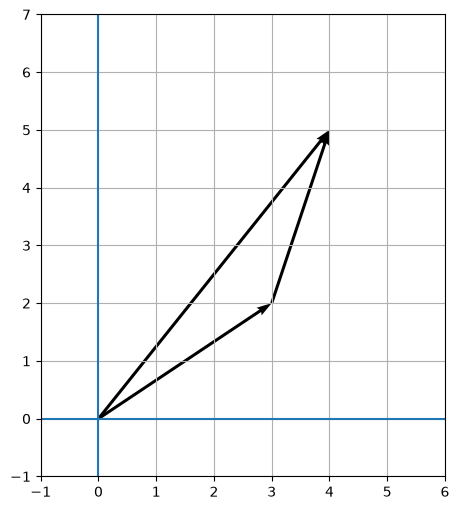

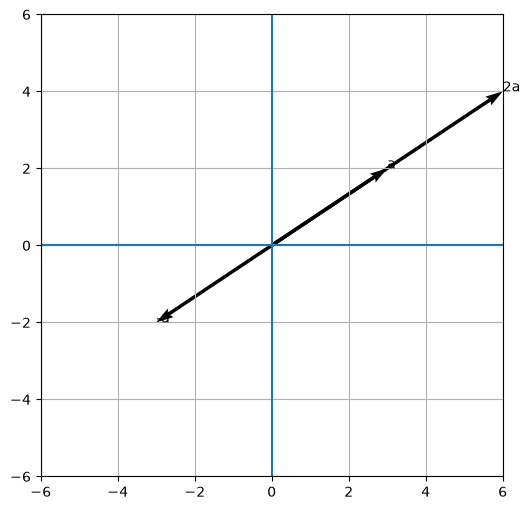

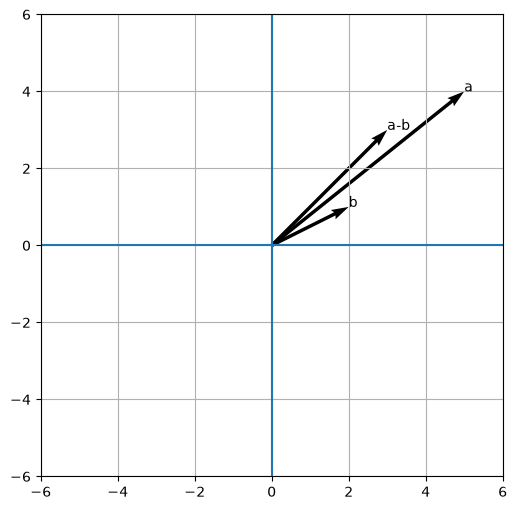

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))

# Vector a: starts at origin
ax.quiver(0, 0, 3, 2,
          angles='xy', scale_units='xy', scale=1)

# Vector b: starts at the tip of a
ax.quiver(3, 2, 1, 3,
          angles='xy', scale_units='xy', scale=1)

# Resultant vector: starts at origin
ax.quiver(0, 0, 4, 5,
          angles='xy', scale_units='xy', scale=1)

ax.set_aspect('equal')
ax.axhline(0)
ax.axvline(0)
ax.grid(True)
ax.set_xlim(-1, 6)
ax.set_ylim(-1, 7)

plt.show()

draw_vectors(
    [a, a*2, a*-1],
    ['a', '2a', '-a']
)

a = np.array([5, 4])
b = np.array([2, 1])

result = a - b

draw_vectors(
    [a, b, result],
    ['a', 'b', 'a-b']
)

In [ ]:
import numpy as np

def angle_between(a, b):
    cos = (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

    cos = np.clip(cos, -1, 1)

    return np.degrees(np.arccos(cos))


# Test 1: Identical vectors
a = np.array([3, 2])
b = np.array([3, 2])

print("Identical vectors:", angle_between(a, b))


# Test 2: Perpendicular vectors
a = np.array([1, 0])
b = np.array([0, 1])

print("Perpendicular vectors:", angle_between(a, b))


# Test 3: Opposite vectors
a = np.array([1, 0])
b = np.array([-1, 0])

print("Opposite vectors:", angle_between(a, b))

Identical vectors: 0.0
Perpendicular vectors: 90.0
Opposite vectors: 180.0
0.0


In [22]:
a = np.array([1, 0])

b = np.array([0, 1])

c = np.array([-1, 0])

print("Angle between a and b:", angle_between(a, b))
print("Angle between a and c:", angle_between(a, c))
print("Angle between b and b:", angle_between(b, b))

a = np.array([2, 2])
b = np.array([3, 1])

print("Original angle:", angle_between(a, b))

print("After scaling b:", angle_between(a, 5 * b))




Angle between a and b: 90.0
Angle between a and c: 180.0
Angle between b and b: 0.0
Original angle: 26.565051177077994
After scaling b: 26.565051177077994


In [21]:
student_A = np.array([85, 90, 75, 80])
student_B = np.array([80, 85, 70, 75])

dot = student_A @ student_B

mag_A = np.linalg.norm(student_A)
mag_B = np.linalg.norm(student_B)

cos = dot / (mag_A * mag_B)

print("Dot product:", dot)
print("Magnitude A:", mag_A)
print("Magnitude B:", mag_B)
print("Cosine:", cos)
print("Angle:", angle_between(student_A, student_B))

Dot product: 25700
Magnitude A: 165.37835408541227
Magnitude B: 155.40270267920053
Cosine: 0.9999905374626583
Angle: 0.24925379300158262


In [27]:
import numpy as np

v1 = np.array([1, 1, 0])
v2 = np.array([1, 0, 1])
v3 = np.array([0, 1, 1])

vectors = np.array([v1, v2, v3])

print(vectors.shape)
def gram_schmidt(vectors):
    basis = []

    for v in vectors:
        w = v.astype(float).copy()

    return np.array(basis)

print(gram_schmidt(vectors))

def gram_schmidt(vectors):
    basis = []

    for v in vectors:
        w = v.astype(float).copy()

        for b in basis:
            w = w - (w @ b) * b
            
        norm = np.linalg.norm(w)

        if norm > 1e-10:
            basis.append(w / norm)

    return np.array(basis)

print(gram_schmidt(vectors))

Q = gram_schmidt(vectors)

print(Q @ Q.T)

print("Original rank:", np.linalg.matrix_rank(vectors))
print("New rank:", np.linalg.matrix_rank(Q))

(3, 3)
[]
[[ 0.70710678  0.70710678  0.        ]
 [ 0.40824829 -0.40824829  0.81649658]
 [-0.57735027  0.57735027  0.57735027]]
[[ 1.00000000e+00  1.03018891e-16  7.33073441e-17]
 [ 1.03018891e-16  1.00000000e+00 -1.03593182e-16]
 [ 7.33073441e-17 -1.03593182e-16  1.00000000e+00]]
Original rank: 3
New rank: 3


In [28]:
v1 = np.array([1, 1, 0])
v2 = np.array([1, 0, 1])

# Third vector is the sum of the first two
v3 = v1 + v2

dependent_vectors = np.array([v1, v2, v3])

result = gram_schmidt(dependent_vectors)

print(result)
print("Output shape:", result.shape)

[[ 0.70710678  0.70710678  0.        ]
 [ 0.40824829 -0.40824829  0.81649658]]
Output shape: (2, 3)


In [29]:
Q_numpy, R = np.linalg.qr(vectors.T)

Q_numpy = Q_numpy.T

Q_ours = gram_schmidt(vectors)

print("Our basis:")
print(Q_ours)

print("\nNumPy basis:")
print(Q_numpy)

Our basis:
[[ 0.70710678  0.70710678  0.        ]
 [ 0.40824829 -0.40824829  0.81649658]
 [-0.57735027  0.57735027  0.57735027]]

NumPy basis:
[[-0.70710678 -0.70710678 -0.        ]
 [ 0.40824829 -0.40824829  0.81649658]
 [-0.57735027  0.57735027  0.57735027]]


Angle: 0°, Dot product: 1.0000000000
Angle: 90°, Dot product: 0.0000000000
Angle: 180°, Dot product: -1.0000000000


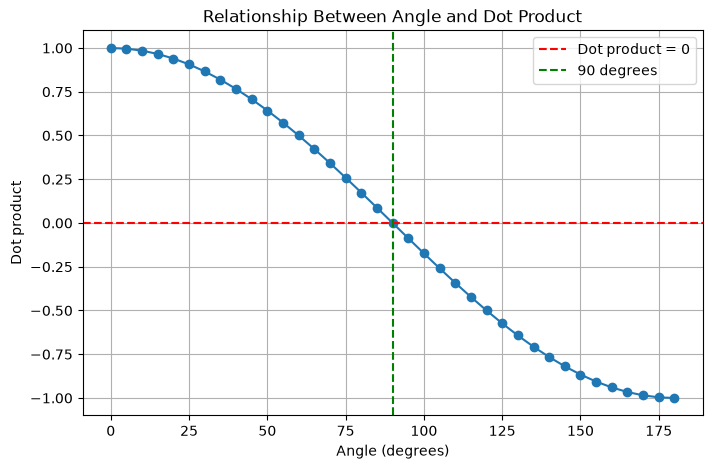

At 90 degrees: 6.123233995736766e-17
Near-zero dot product at angle: 90


In [4]:
import numpy as np
import matplotlib.pyplot as plt


angles, dots = [], []

base = np.array([1.0, 0.0])

for deg in range(0, 181, 5):
    rad = np.radians(deg)
    v = np.array([np.cos(rad), np.sin(rad)])

    angles.append(deg)
    dots.append(base @ v)
    
for angle, dot in zip(angles, dots):
    if angle in [0, 90, 180]:
        print(f"Angle: {angle}°, Dot product: {dot:.10f}")
        
        



plt.figure(figsize=(8, 5))

plt.plot(angles, dots, marker='o')

plt.axhline(0, color='red', linestyle='--', label='Dot product = 0')
plt.axvline(90, color='green', linestyle='--', label='90 degrees')

plt.xlabel("Angle (degrees)")
plt.ylabel("Dot product")
plt.title("Relationship Between Angle and Dot Product")

plt.legend()
plt.grid()
plt.show()


for angle, dot in zip(angles, dots):

    if angle == 90:
        print("At 90 degrees:", dot)

    if abs(dot) < 1e-10:
        print("Near-zero dot product at angle:", angle)

Dot product: 0
Vector A: [1. 0.]
Vector B: [0.70710678 0.70710678]
Dot product: 0.7071067811865476
Dot product: 0.9961946980917455


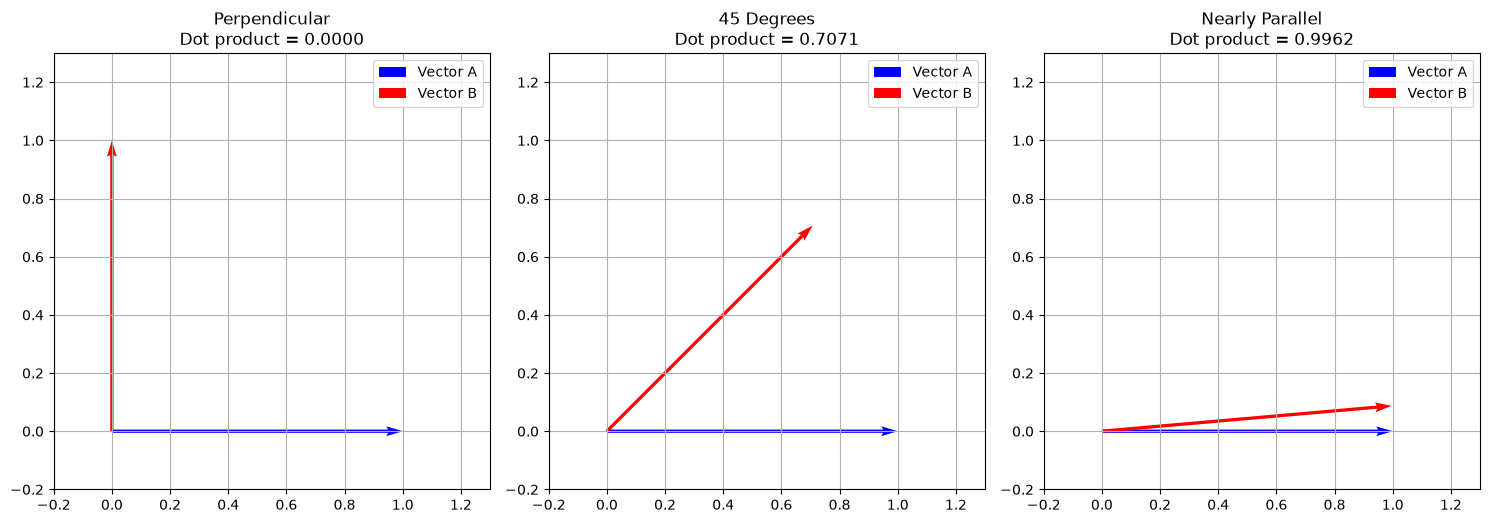

In [ ]:
a = np.array([1, 0])
b = np.array([0, 1])

dot = a @ b

print("Dot product:", dot)

a = np.array([1.0, 0.0])
b = np.array([np.cos(np.radians(45)),
              np.sin(np.radians(45))])

dot = a @ b

print("Vector A:", a)
print("Vector B:", b)
print("Dot product:", dot)

a = np.array([1.0, 0.0])
b = np.array([
    np.cos(np.radians(5)),
    np.sin(np.radians(5))
])

dot = a @ b

print("Dot product:", dot)




pairs = [
    (np.array([1, 0]), np.array([0, 1]), "Perpendicular"),
    (np.array([1, 0]), np.array([np.cos(np.radians(45)),
                                 np.sin(np.radians(45))]), "45 Degrees"),
    (np.array([1, 0]), np.array([np.cos(np.radians(5)),
                                 np.sin(np.radians(5))]), "Nearly Parallel")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (a, b, title) in zip(axes, pairs):

    dot = a @ b

    ax.quiver(0, 0, a[0], a[1],
              angles='xy', scale_units='xy', scale=1,
              color='blue', label='Vector A')

    ax.quiver(0, 0, b[0], b[1],
              angles='xy', scale_units='xy', scale=1,
              color='red', label='Vector B')

    ax.set_title(f"{title}\nDot product = {dot:.4f}")
    ax.set_xlim(-0.2, 1.3)
    ax.set_ylim(-0.2, 1.3)
    ax.set_aspect('equal')
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

"""The dot product formula is \(A \cdot B = |A||B|\cos(\theta)\). For two non-zero vectors, 
if their dot product is zero, then \(\cos(\theta)=0\),
which means the angle between them is 90°. Therefore, the vectors are perpendicular."""

In [15]:
docs = np.array([
    [8, 6, 4, 0, 0, 1],  # Document 1: Machine Learning
    [5, 7, 6, 0, 0, 0],  # Document 2: AI and Data
    [0, 1, 0, 7, 8, 6],  # Document 3: Cooking
    [0, 0, 0, 5, 6, 8],  # Document 4: Food Recipes
    [6, 5, 3, 6, 0, 0]   # Document 5: Mixed vocabulary
])

print(docs)
print("Shape:", docs.shape)

query = np.array([9, 7, 5, 0, 0, 0])
def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

similarities = []

for doc in docs:
    score = cosine_similarity(query, doc)
    similarities.append(score)

print(similarities)

ranked_indices = np.argsort(similarities)[::-1]

for index in ranked_indices:
    print(
        f"Document {index + 1}: "
        f"Similarity = {similarities[index]:.4f}"
    )
    
short_doc = np.array([2, 3, 1, 0, 0, 0])

long_doc = np.array([10, 15, 5, 0, 0, 0])
similarity = cosine_similarity(short_doc, long_doc)

print("Cosine similarity between long_doc and short_doc:", similarity)

[[8 6 4 0 0 1]
 [5 7 6 0 0 0]
 [0 1 0 7 8 6]
 [0 0 0 5 6 8]
 [6 5 3 6 0 0]]
Shape: (5, 6)
[np.float64(0.9950525532241855), np.float64(0.9496410805236797), np.float64(0.04590780850487671), np.float64(0.0), np.float64(0.8113618016764901)]
Document 1: Similarity = 0.9951
Document 2: Similarity = 0.9496
Document 5: Similarity = 0.8114
Document 3: Similarity = 0.0459
Document 4: Similarity = 0.0000
Cosine similarity between long_doc and short_doc: 1.0


In [ ]:
dot_scores = []

for doc in docs:
    score = query @ doc
    dot_scores.append(score)

print("Raw dot product scores:", dot_scores)

dot_ranking = np.argsort(dot_scores)[::-1]

print("\nRanking using raw dot product:")

for index in dot_ranking:
    print(f"Document {index + 1}: Score = {dot_scores[index]}")
    
print("Short document:", query @ short_doc)
print("Long document:", query @ long_doc)


"""Cosine similarity compares the direction rather than the magnitude like the dot product,
cause dot produc will differ too much and will give higher similarity to document with higher magnitude"""



Raw dot product scores: [np.int64(134), np.int64(124), np.int64(7), np.int64(0), np.int64(104)]

Ranking using raw dot product:
Document 1: Score = 134
Document 2: Score = 124
Document 5: Score = 104
Document 3: Score = 7
Document 4: Score = 0
Short document: 44
Long document: 220


In [21]:
import numpy as np

rng = np.random.default_rng(0)

height_cm = rng.normal(170, 10, 100)
height_in = height_cm / 2.54

weight = rng.normal(70, 15, 100)
age = rng.integers(18, 65, 100)
exercise_hours = rng.normal(5, 2, 100)

X = np.column_stack((
    height_cm,
    height_in,
    weight,
    age,
    exercise_hours
))

print("Feature matrix shape:", X.shape)
print(X[:5])
rank = np.linalg.matrix_rank(X)
print("Matrix rank:", rank)
correlation = np.corrcoef(X, rowvar=False)
print(np.round(correlation, 3))

X_reduced = np.delete(X, 1, axis=1)
print("Original shape:", X.shape)
print("Reduced shape:", X_reduced.shape)
print("Original rank:", np.linalg.matrix_rank(X))
print("Reduced rank:", np.linalg.matrix_rank(X_reduced))

Feature matrix shape: (100, 5)
[[171.25730221  67.42413473  77.54024275  45.           4.35105629]
 [168.67895137  66.40903597  84.8456955   27.           2.5575533 ]
 [176.4042265   69.45048288  67.53558111  48.           5.40382   ]
 [171.04900117  67.34212645  53.88452713  45.           4.92232992]
 [164.64330627  64.82019932  83.09563229  61.           7.13264911]]
Matrix rank: 4
[[ 1.     1.     0.055 -0.088 -0.041]
 [ 1.     1.     0.055 -0.088 -0.041]
 [ 0.055  0.055  1.     0.073  0.054]
 [-0.088 -0.088  0.073  1.    -0.106]
 [-0.041 -0.041  0.054 -0.106  1.   ]]
Original shape: (100, 5)
Reduced shape: (100, 4)
Original rank: 4
Reduced rank: 4
